# 15 普通HTTPS镜像：两例真实MRI下载与技术验证

用户已批准替代路线，不以官方原始来源认证为前提。0002_01与0005_01按固定清单下载12文件，原始文件名与内容不改写。见`reports/ucsd_mri_mirror_sample_plan.md`。这两例仅供技术验证，不估计诊断性能。

In [1]:
from pathlib import Path
import sys,json,runpy,hashlib
import numpy as np
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from rn_public.ucsd_mri_mirror import run,SAMPLE_IDS
s=run(ROOT)
print(json.dumps(s,indent=2))
assert s['successful_download_files']==s['decoded_image_files']==12
assert s['sample_two_ID_bindings_match'] is True

{
  "checked_at_utc": "2026-10-29T05:41:44.042522+00:00",
  "route": "public GitHub release HTTPS; no Aspera",
  "sample_IDs": [
    "UCSD-PTGBM-0002_01",
    "UCSD-PTGBM-0005_01"
  ],
  "requested_image_files": 12,
  "successful_download_files": 12,
  "downloaded_image_bytes": 14251565,
  "decoded_image_files": 12,
  "technical_pass_image_files": 0,
  "grid_screen_pass_files": 0,
  "relative_native_grid_matches": 12,
  "unknown_spatial_unit_files": 12,
  "uint8_intensity_files": 10,
  "sample_two_ID_bindings_match": true,
  "mirror_listed_FLAIR_timepoints": 184,
  "remaining_clinical_timepoints": 238,
  "remaining_clinical_patients": 176,
  "listed_all_six_remaining_timepoints": 182,
  "listed_all_six_remaining_patients": 135,
  "listed_all_six_tumor_timepoints": 141,
  "listed_all_six_treatment_change_timepoints": 41,
  "entire_mirror_downloaded": false,
  "clinical_models_refitted": false,
  "MRI_model_fitted": false,
  "prediction_features_extracted": false,
  "ROI_for_prediction_a

## 临床连接及目录覆盖

镜像清单不是下载结果。184个FLAIR目录中，隔离已知ID冲突后，有182个时间点可与现有临床表连接；当前只取得两例12文件。病例通过显式镜像ID与BraTS ID核对，标签仍沿用第13步源表。

In [2]:
base=ROOT/'reports/ucsd_mri_mirror'
coverage=pd.read_csv(base/'clinical_mirror_sequence_coverage.csv')
mapping=pd.read_csv(base/'sample_case_mapping.csv')
display(mapping)
display(coverage.groupby(['listed_all_six','tumor_label']).agg(timepoints=('ID','size'),source_patients=('patient_id','nunique')))
assert len(coverage)==238 and coverage.patient_id.nunique()==176
assert coverage.actual_download_complete.sum()==2
assert set(mapping.ID)==set(SAMPLE_IDS)

,ID,mirror_metadata_ID,brats_ID,patient_id,tumor_label,label_source,two_identifier_fields_match
0,UCSD-PTGBM-0002_01,sub-0002_01,BraTS-GLI-02251-100,UCSD-PTGBM-0002,0,explicit_negative_case_list,True
1,UCSD-PTGBM-0005_01,sub-0005_01,BraTS-GLI-02254-100,UCSD-PTGBM-0005,1,derived_from_published_243_equals_192_plus_51_...,True


timepoints  source_patients
listed_all_six tumor_label                             
False          0                    10               10
               1                    46               34
True           0                    41               29
               1                   141              114

## 完整体素与两种网格检查

12份文件均可解码，但空间单位unknown，预设物理尺度检查仍未通过。所有强度序列为uint8、slope=1、intercept=0，值域0–255；不把ADC解释成原始物理量。新增无单位的原生仿射比较只用于同体素索引叠加，不赋予毫米或临床配准通过。

In [3]:
qc=pd.read_csv(base/'sample_file_qc.csv')
display(qc[['ID','sequence','shape','stored_dtype','spatial_units','minimum','maximum','decoded','relative_grid_status','technical_pass','issues']])
receipt=json.loads((base/'sample_qc_receipt.json').read_text())
assert all(r['gzip_crc_verified'] and r['release_digest_matches'] for r in receipt['files'])
assert s['unknown_spatial_unit_files']==12
assert s['relative_native_grid_matches']==12
assert s['technical_pass_image_files']==0
assert all(r['nonfinite_voxels']==0 for r in receipt['files'])

,ID,sequence,shape,stored_dtype,spatial_units,minimum,maximum,decoded,relative_grid_status,technical_pass,issues
0,UCSD-PTGBM-0002_01,ADC_vendor,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
1,UCSD-PTGBM-0002_01,BraTS_tumor_seg,256x256x256,uint8,unknown,0.0,4.0,True,native_matrix_match,False,unknown_spatial_units
2,UCSD-PTGBM-0002_01,FLAIR,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
3,UCSD-PTGBM-0002_01,T1post,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
4,UCSD-PTGBM-0002_01,T1pre,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
5,UCSD-PTGBM-0002_01,T2,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
6,UCSD-PTGBM-0005_01,ADC_vendor,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
7,UCSD-PTGBM-0005_01,BraTS_tumor_seg,256x256x256,uint8,unknown,0.0,4.0,True,native_matrix_match,False,unknown_spatial_units
8,UCSD-PTGBM-0005_01,FLAIR,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units
9,UCSD-PTGBM-0005_01,T1post,256x256x256,uint8,unknown,0.0,255.0,True,native_matrix_match,False,unknown_spatial_units


## 真实图像预览

下图来自实际镜像文件，非测试数组。切片按FLAIR非零包围盒中点固定选择，不按临床类别或分割大小挑图。仅为头部方向下的技术预览，原文件不写回、不注册；分割颜色只表示观察到的整数值。

Saved three actual-image technical previews


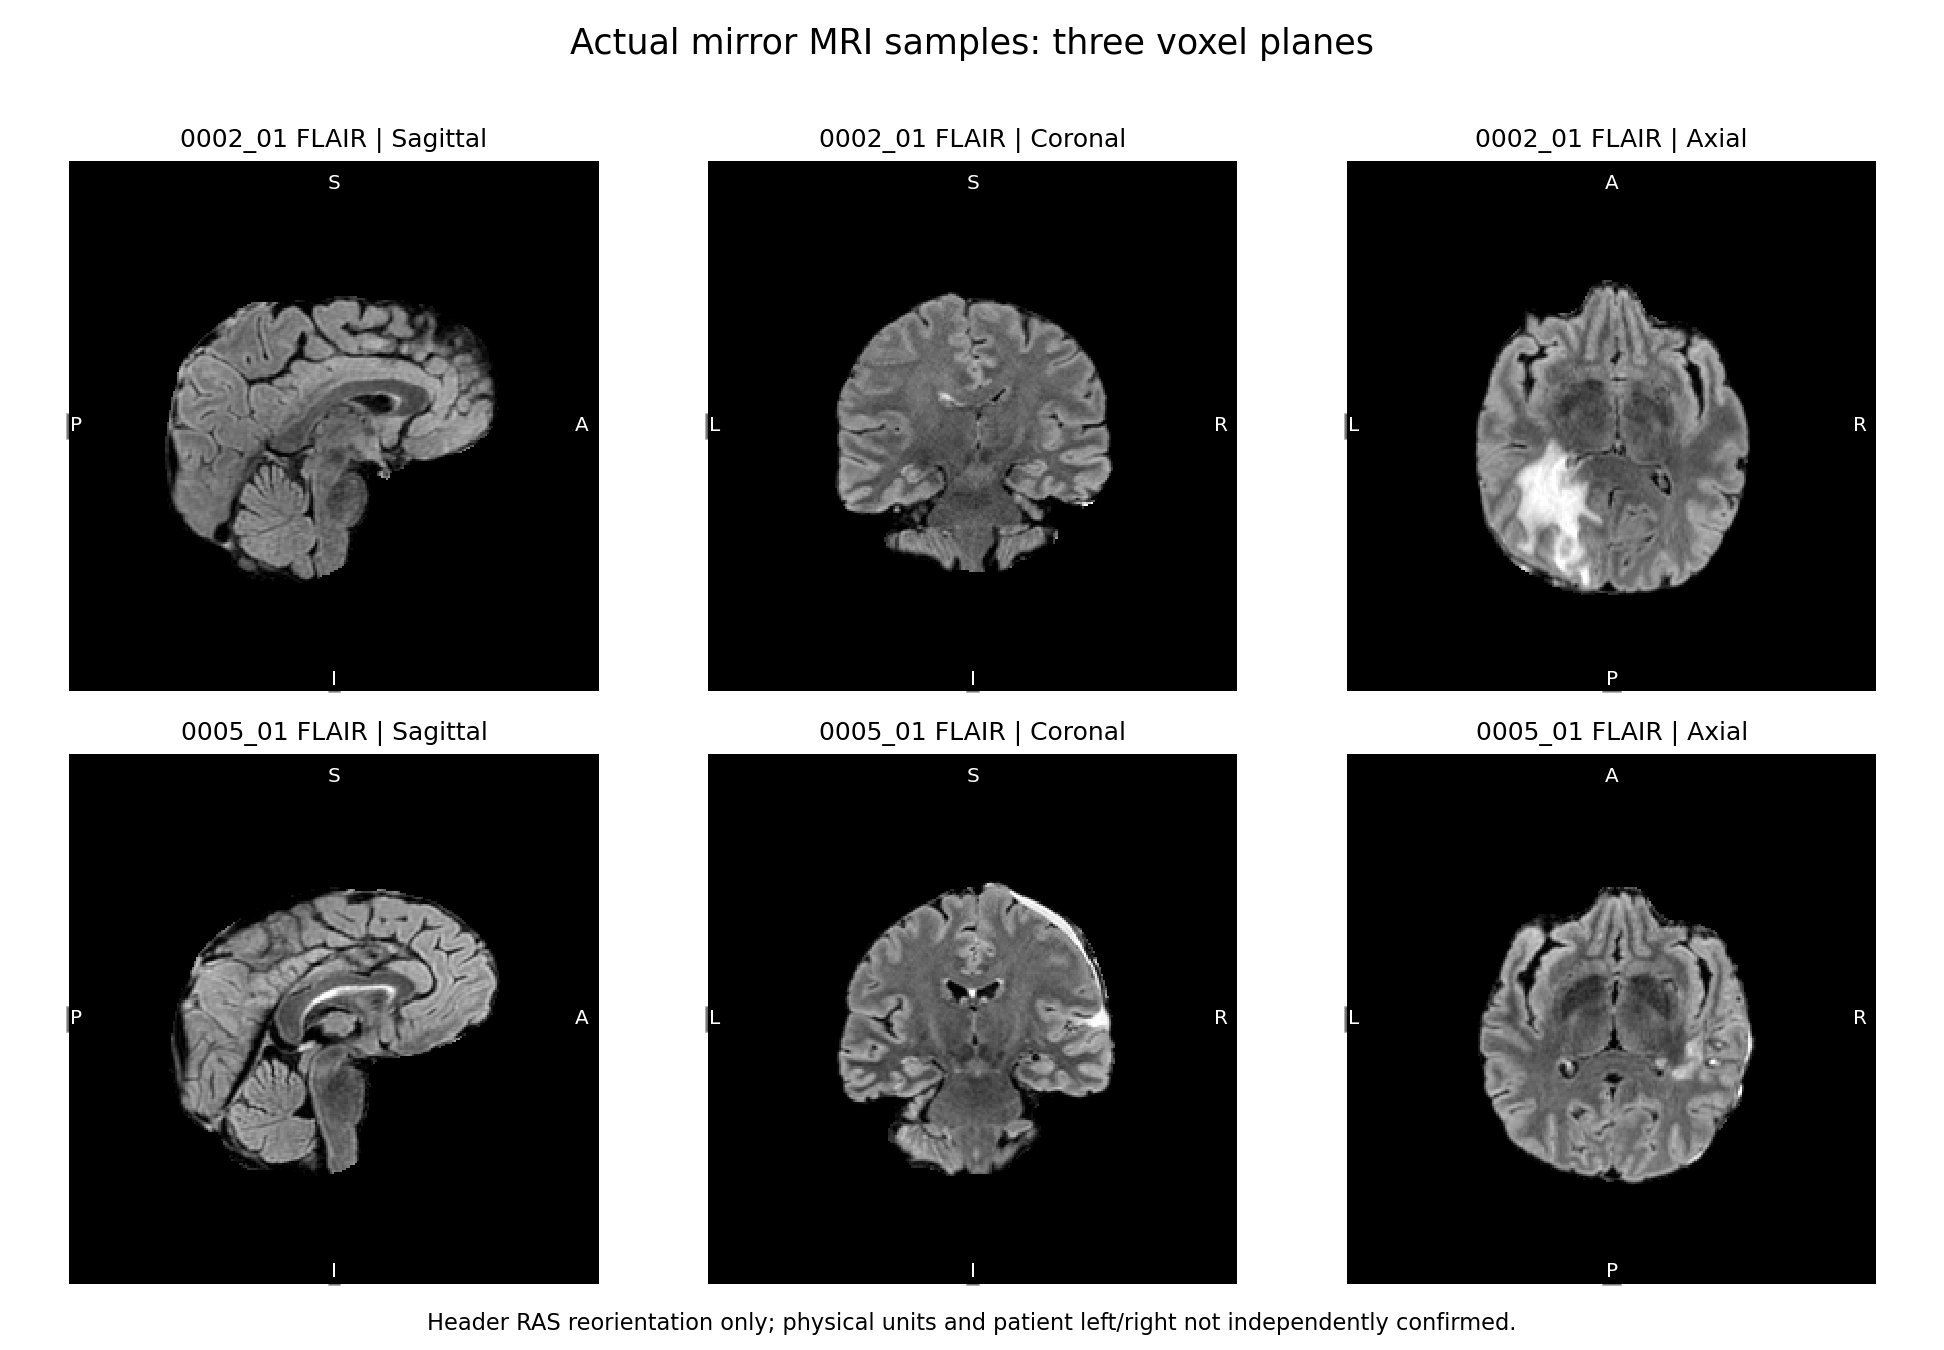

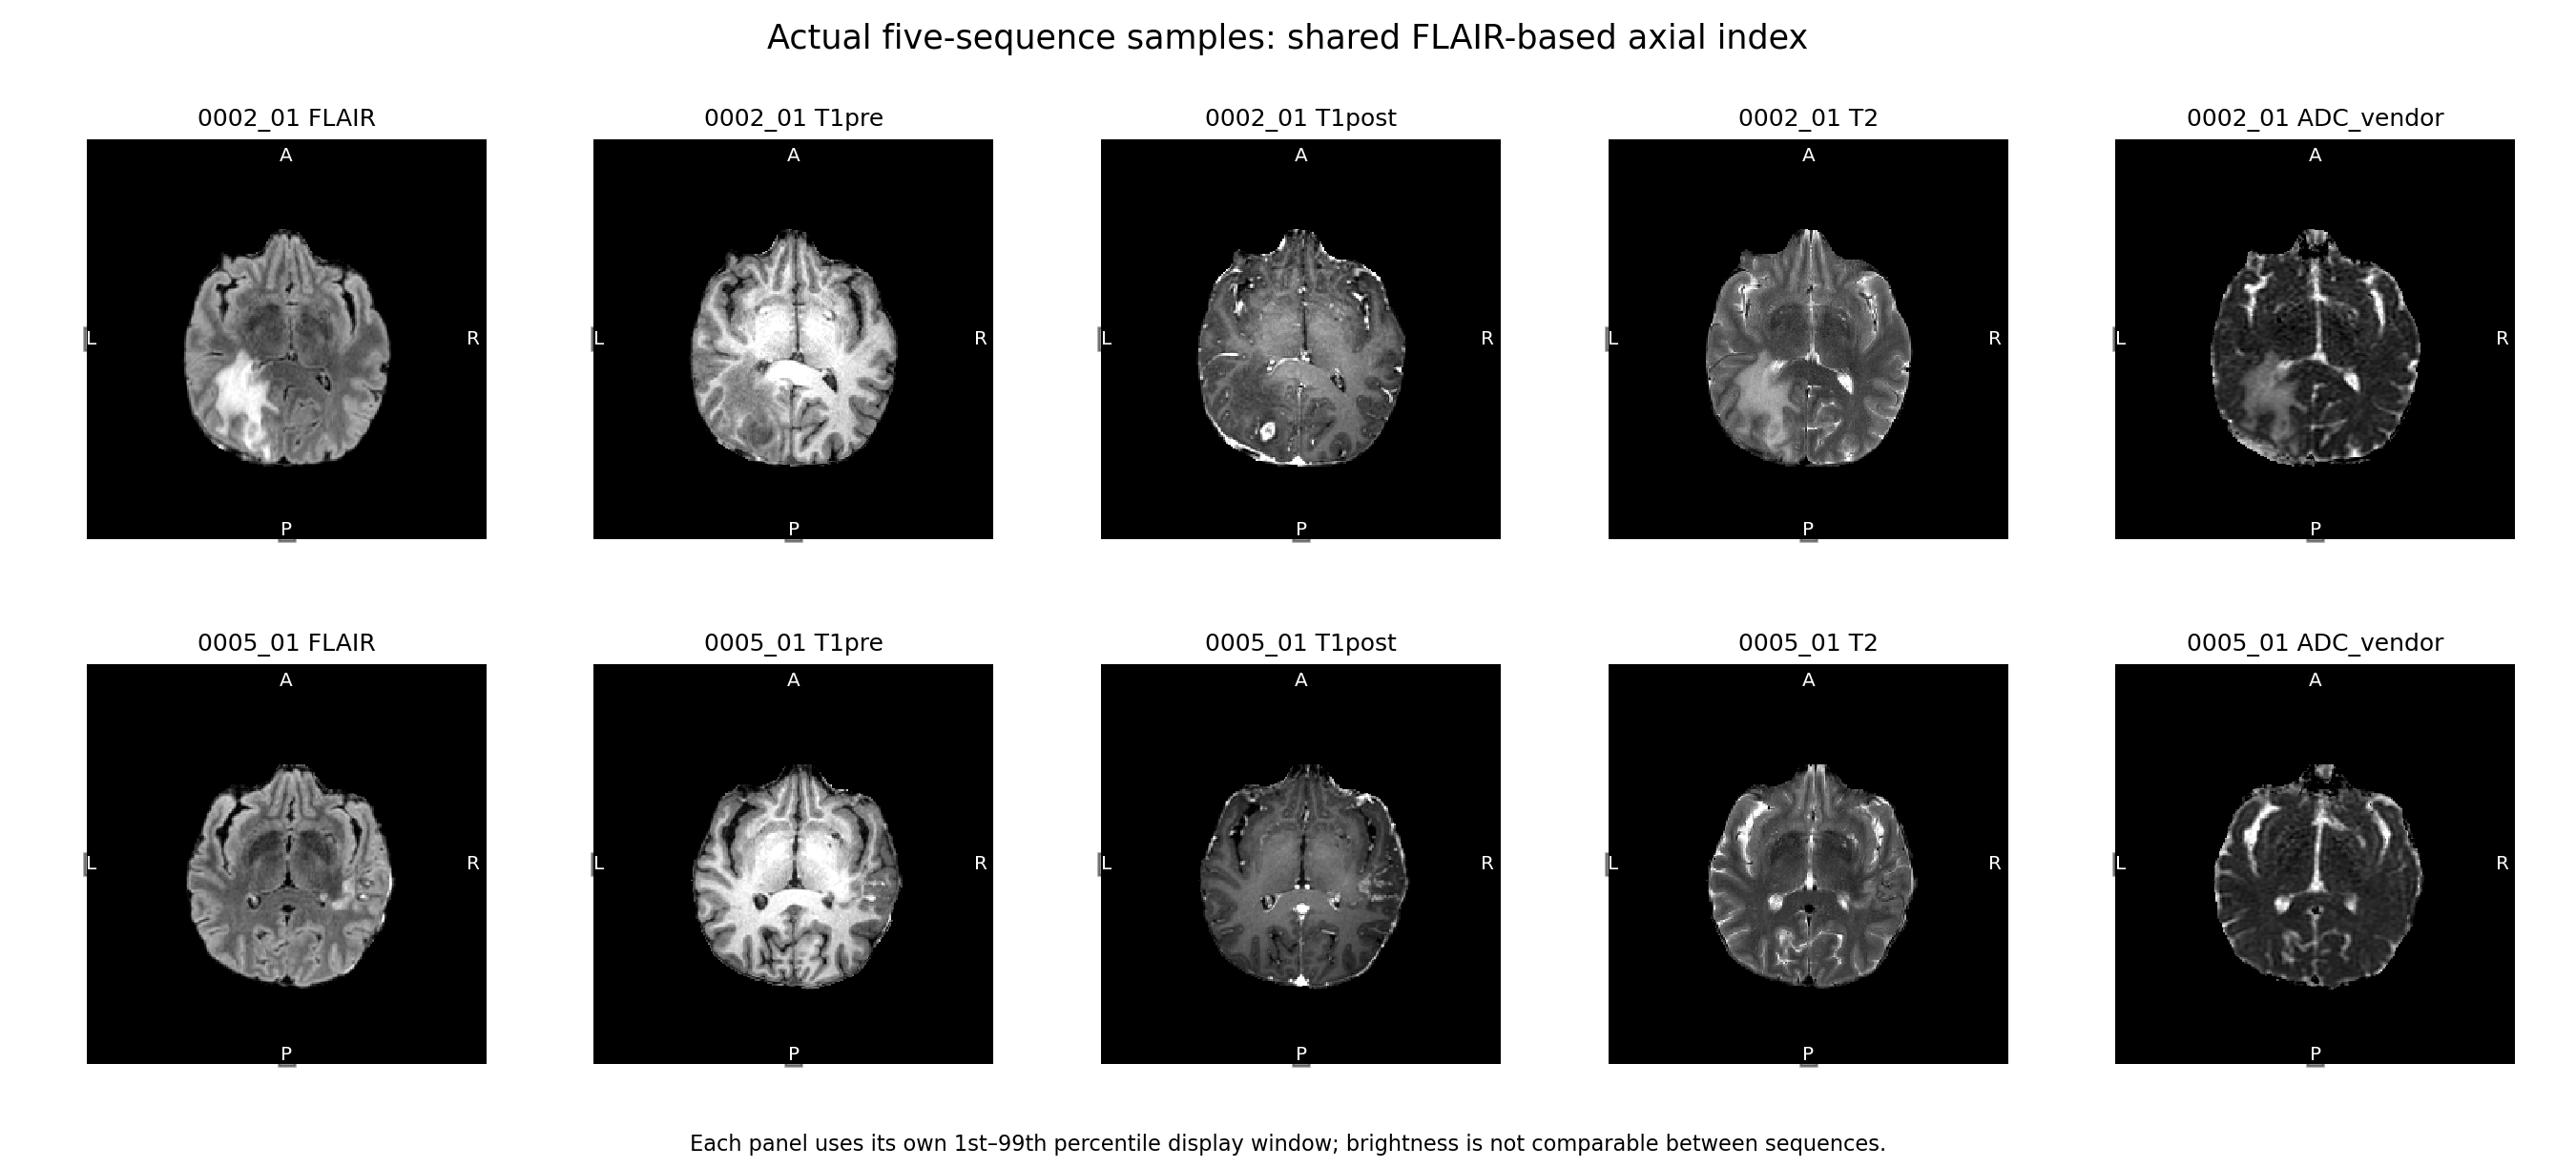

In [4]:
runpy.run_path(str(ROOT/'scripts/plot_ucsd_mirror_samples.py'),run_name='__main__')
for name in ['actual_FLAIR_planes.png','actual_multisequence_axial.png','actual_segmentation_overlay.png']:
    display(Image(filename=str(ROOT/'outputs/ucsd-mri-mirror-20261029'/name)))

## 本步结果与限制

下载和解码路线已打通，用户无需手动下载；物理尺度、定量强度和统一预测ROI仍有待解决。未下载细胞性参考分割，未提取预测特征，未训练MRI模型，也未重训临床模型。下一研究阶段按用户要求等待批准。

{
  "checked_at_utc": "2026-10-29T05:36:37.828720+00:00",
  "tests_run": 61,
  "failures": 0,
  "errors": 0,
  "skipped": 0,
  "success": true,
  "elapsed_seconds": 4.089,
  "new_mirror_test_cases": 4,
  "real_sample_files_tested_by_synthetic_tests": 0
}


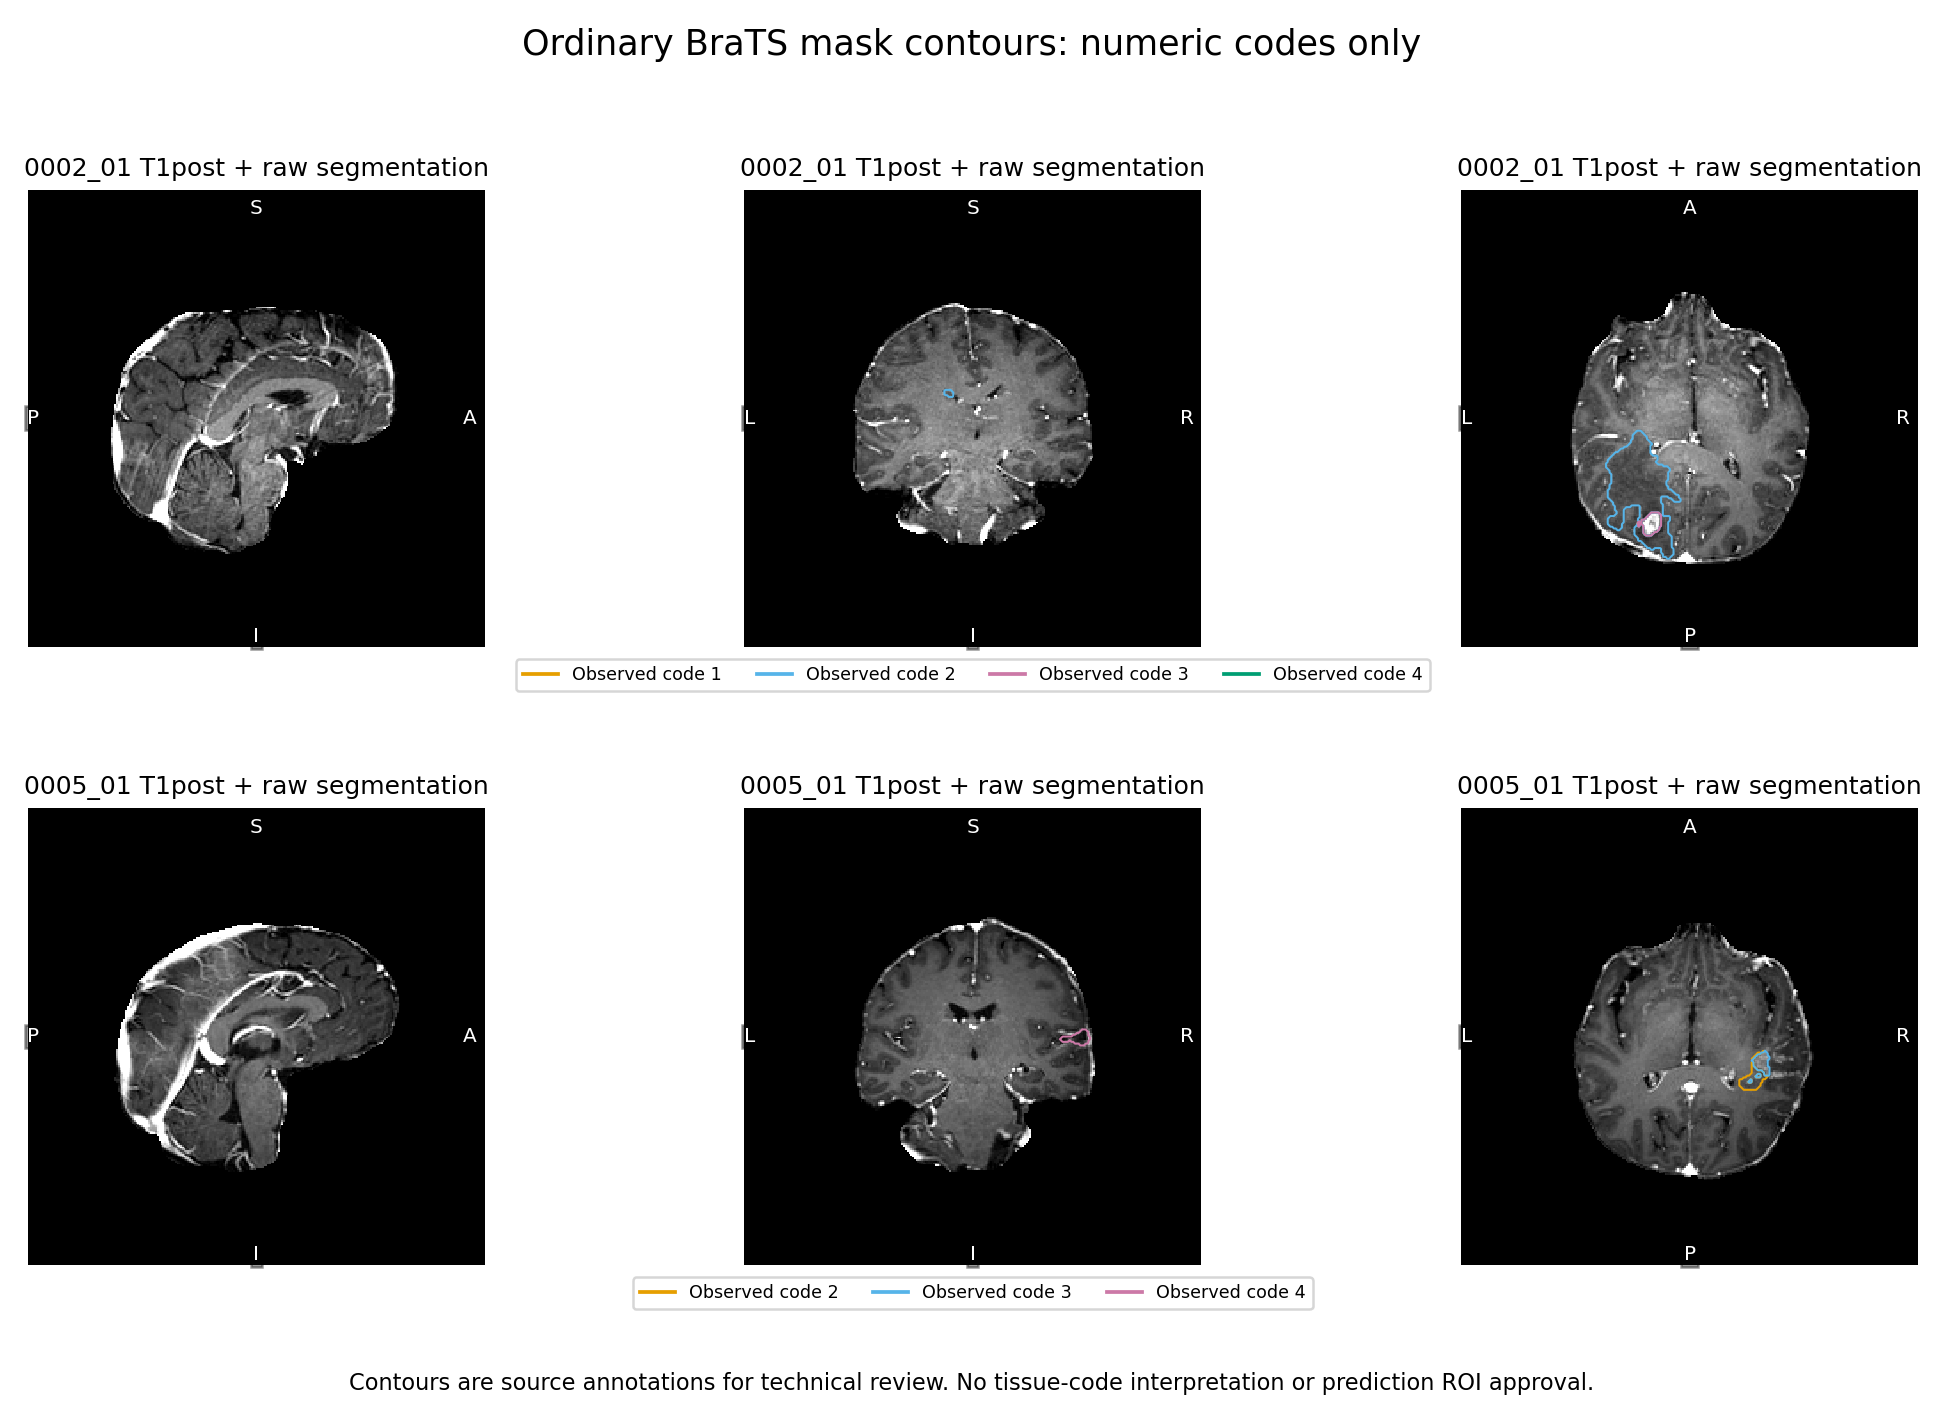

Actual sample acquisition/decoding completed. Physical-scale acceptance and prediction ROI remain incomplete.


In [5]:
tests=json.loads((base/'software_test_receipt.json').read_text())
print(json.dumps(tests,indent=2))
assert tests['success']
assert not s['MRI_model_fitted'] and not s['clinical_models_refitted']
assert not s['prediction_features_extracted'] and not s['ROI_for_prediction_approved']
assert s['code_sha256']==hashlib.sha256((ROOT/'src/rn_public/ucsd_mri_mirror.py').read_bytes()).hexdigest()
print('Actual sample acquisition/decoding completed. Physical-scale acceptance and prediction ROI remain incomplete.')